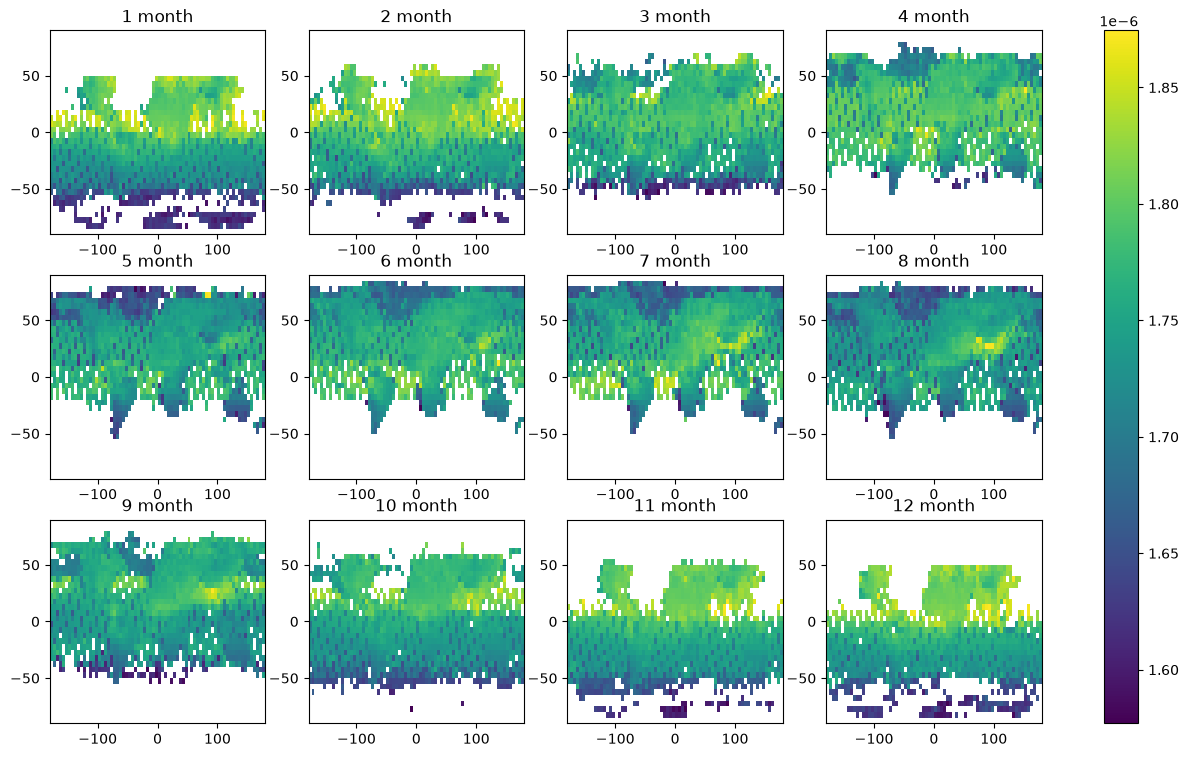

In [102]:
#problem 1.1

import netCDF4
import xarray as xr

import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
from matplotlib import pyplot as plt

data = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc", engine="netcdf4")

#clear the data
fill=data.xch4.attrs['fill_value']
data['xch4']=data.xch4.where(data.xch4 < fill)

#draw
mon = data.xch4.groupby('time.month').mean()
fig=plt.figure(figsize=(16,9))

for i in range(12):
    ax=plt.subplot(3,4,i+1)
    im=mon.isel(month=i).plot(add_colorbar=False)
    plt.title(str(i+1)+' month')
    ax.set_xlabel('')
    ax.set_ylabel('')
    
fig.colorbar(im,ax=fig.axes)

plt.show()




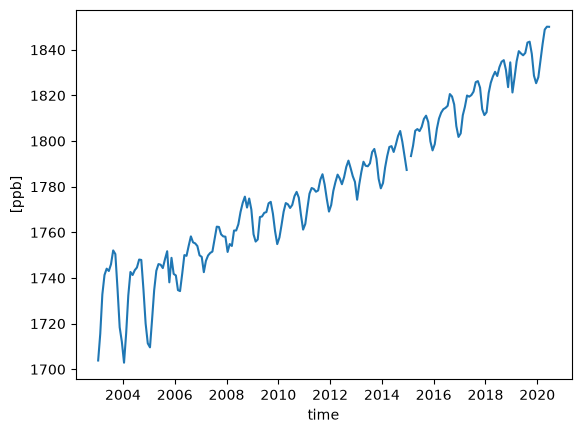

In [103]:
#problem 1.2

#caculate
pro2=data.xch4.mean(dim=['lat','lon'])*1e9


#draw
pro2.plot()
plt.ylabel('[ppb]')
plt.show()

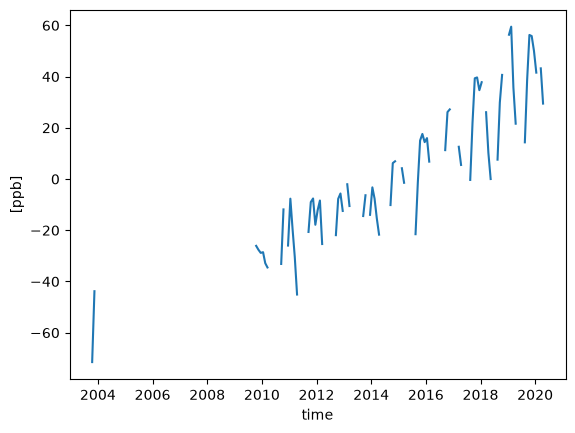

In [104]:
#problem 1.3

#get the local data
point=data.xch4.sel(lat=-15,lon=210,method='nearest')

#calculate the result
group=point.groupby('time.month')
m=group.mean(dim='time')
result=(group-m)*1e9

result.plot()
plt.ylabel('[ppb]')

plt.show()

In [105]:
#problem 2.1
ques2 = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc", engine="netcdf4")
ques2
#calculate for monthly data
a01=ques2.sst.sel(lat=slice(-5,5),lon=slice(190,240))
a02=a01.mean(dim=['lat','lon'])

group=a02.groupby('time.month')
cm=group.mean(dim='time')

juping=group-cm

cm
juping

<xarray.DataArray 'sst' (time: 684)> Size: 3kB
array([-3.19580078e-01, -4.68521118e-01, -2.68152237e-01, -1.86965942e-01,
       -1.77598953e-01, -3.57690811e-01, -1.41969681e-01,  1.46579742e-02,
       -1.52217865e-01, -3.79863739e-01, -3.60893250e-01, -2.08698273e-01,
       -1.91473007e-01, -1.34283066e-01, -2.40375519e-01, -1.85125351e-01,
        5.19142151e-02,  2.39383698e-01, -7.03392029e-02, -4.18693542e-01,
       -7.78316498e-01, -7.92383194e-01, -4.96292114e-01, -4.17312622e-01,
       -4.44782257e-01, -4.55940247e-01, -4.36033249e-01, -4.66926575e-01,
       -5.64533234e-01, -4.26885605e-01, -2.76725769e-01, -3.17211151e-01,
       -6.73160553e-01, -6.66116714e-01, -8.17707062e-01, -8.65488052e-01,
       -7.01400757e-01, -3.57038498e-01,  6.96258545e-02,  1.73400879e-01,
       -9.06715393e-02,  7.69157410e-02,  6.87641144e-01,  7.95261383e-01,
        7.12978363e-01,  8.34251404e-01,  9.08538818e-01,  1.08588409e+00,
        8.51554871e-01,  5.23397446e-01, -1.30540848e-01, -6.34363174e-01,
       -8.61984253e-01, -9.45945740e-01, -7.84175873e-01, -1.09434509e+00,
       -1.25451660e+00, -1.18983459e+00, -1.29195786e+00, -1.20479774e+00,
       -7.82999039e-01, -3.68686676e-01, -1.12600327e-01, -7.66296387e-02,
        2.68373489e-01,  5.91150284e-01,  8.12013626e-01,  1.23806953e+00,
        1.27759552e+00,  1.52435493e+00,  1.58320427e+00,  1.44117928e+00,
        1.17595100e+00,  9.12748337e-01,  9.74021912e-01,  5.48082352e-01,
       -1.27168655e-01,  1.68796539e-01,  2.07981110e-01, -1.75546646e-01,
...
       -1.43000221e+00, -1.45662498e+00, -1.37596893e+00, -1.35082245e+00,
       -1.47319794e+00, -1.05743599e+00, -8.56203079e-01, -4.86505508e-01,
       -1.43491745e-01,  4.29821014e-02, -1.12358093e-01, -3.01353455e-01,
       -5.81169128e-01, -7.46503830e-01, -9.97226715e-01, -1.00194931e+00,
       -7.01192856e-01, -5.66352844e-01, -3.01475525e-01, -1.52109146e-01,
       -8.46328735e-02,  7.59525299e-02,  1.72380447e-01,  3.80491257e-01,
        8.36544037e-01,  6.27601624e-01,  4.97859955e-01, -3.83163452e-01,
       -6.95632935e-01, -5.49228668e-01, -3.67496490e-01,  9.52854156e-02,
       -3.93390656e-02, -2.35013962e-01, -2.66674042e-01, -2.96995163e-01,
       -2.14775085e-01, -8.15982819e-02, -1.58285141e-01, -3.91717911e-01,
       -5.38036346e-01, -6.71432495e-01, -3.81156921e-01,  2.24323273e-02,
        3.64341736e-01,  2.08318710e-01,  8.80393982e-02, -1.83677673e-03,
        2.54846573e-01,  5.18692017e-01,  8.60204697e-01,  7.23587036e-01,
        6.23178482e-01,  5.44242859e-01,  5.93399048e-01,  9.04596329e-01,
        1.00379372e+00,  1.14265823e+00,  1.40406609e+00,  1.65553093e+00,
        1.91476250e+00,  2.32380676e+00,  2.70230293e+00,  2.52171326e+00,
        2.46178627e+00,  2.14286995e+00,  1.61798477e+00,  1.15098190e+00,
        4.64086533e-01, -1.12237930e-01, -5.67394257e-01, -6.47745132e-01,
       -6.40022278e-01, -8.96675110e-01, -9.70773697e-01, -8.55260849e-01],
      dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
    month    (time) int64 5kB 1 2 3 4 5 6 7 8 9 10 11 ... 3 4 5 6 7 8 9 10 11 12
Attributes:
    pointwidth:          1.0
    valid_min:           -3.0
    valid_max:           45.0
    units:               degree_Celsius
    long_name:           Extended reconstructed sea surface temperature
    standard_name:       sea_surface_temperature
    iridl:hasSemantics:  iridl:SeaSurfaceTemperature

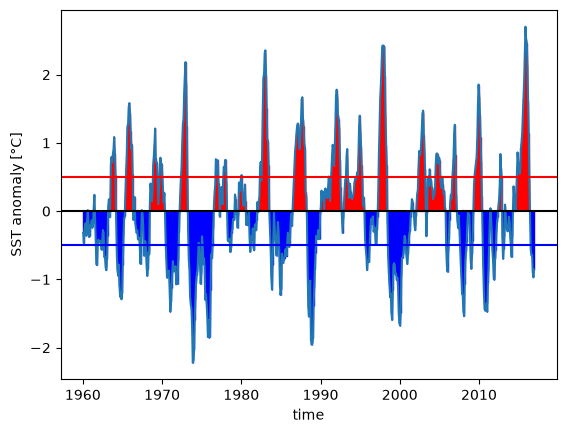

In [106]:
# problem 2.2
juping.plot()

#补充图中的标识线
plt.axhline(0.5,color='red')
plt.axhline(-0.5,color='blue')
plt.axhline(0,color='black')

plt.ylabel('SST anomaly [°C]')

#绘制补充的柱状图
tu=plt.bar(juping.time,juping)
#用if来判断颜色为红还是蓝
for i in range(len(tu)):
    if juping[i]>=0:
        tu[i].set_color('red')
    else:
        tu[i].set_color('blue')

plt.show()

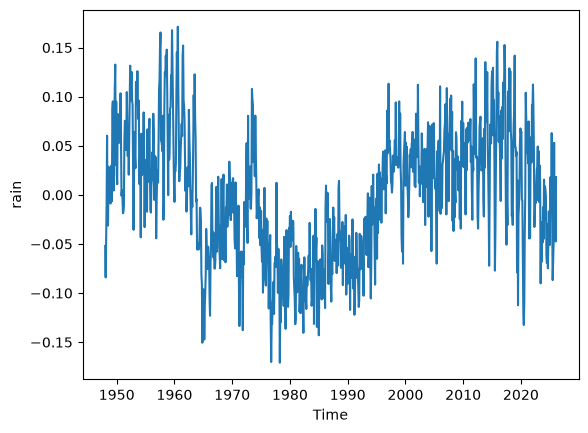

In [107]:
#problem 3.1
pro3 = xr.open_dataset("prate.sfc.mon.mean.nc", engine="netcdf4")
pro3
pro3['prate']=pro3.prate*86400
pro3.prate.attrs['units']='mm/day'


gp=pro3.prate.mean(dim=['lat','lon'])

group=gp.groupby('time.month')
cm=group.mean(dim='time')
result=group-cm

result.plot()
plt.ylabel('rain')
plt.show()

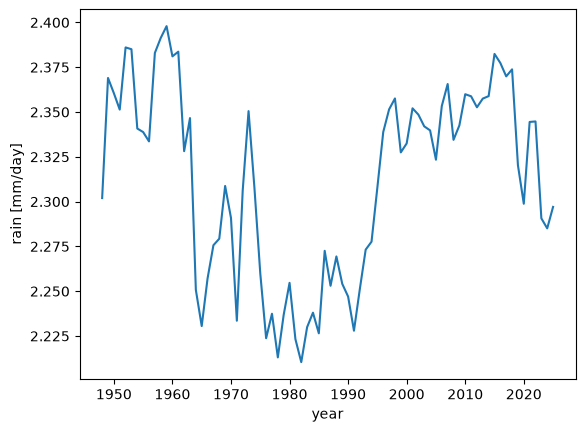

In [108]:
#picture 1 全球年平均降水时间序列
annual=gp.sel(time=slice('1948','2025')).groupby('time.year').mean()

annual.plot()
plt.ylabel('rain [mm/day]')
plt.show()

In [109]:
#picture2 各年各月全球降雨分布图
import hvplot.xarray
import hvplot.xarray
pro3.prate.hvplot()
pro3.prate.isel(time=-1).hvplot(cmap="fire")
pro3.prate.isel(time=-1,lon=100).hvplot()
pro3.prate.hvplot(groupby="time",clim=(0,15),cmap='turbo')

:DynamicMap   [time]
   :Image   [lon,lat]   (Monthly Mean of Precipitation Rate)

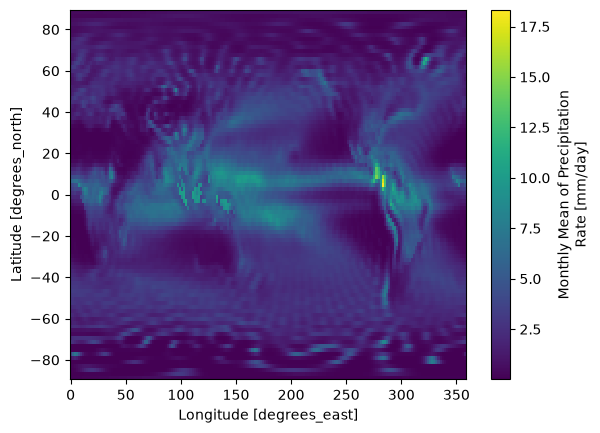

In [110]:
#picture 3 全球多年平均降水分布图
mean_rain=pro3.prate.mean(dim='time')
mean_rain.plot()
plt.show()

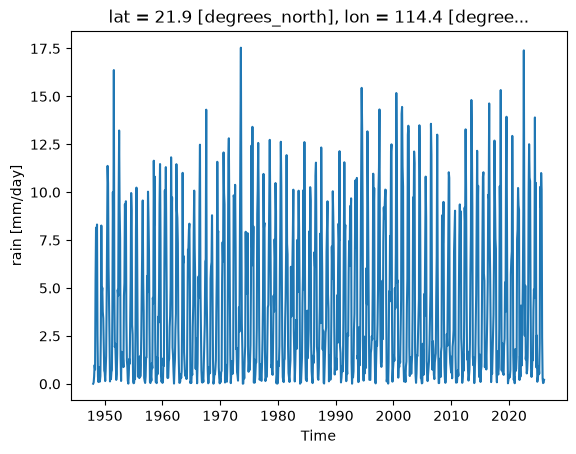

In [111]:
#picture 4 深圳市平均降水的时间序列
shenzhen=pro3.prate.sel(lat=22.5,lon=114,method='nearest')
shenzhen.plot()
plt.ylabel('rain [mm/day]')
plt.show()

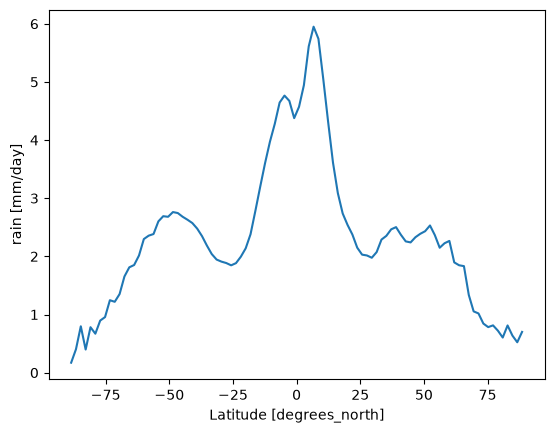

In [112]:
#picture 5 各纬度上平均的降水（平均降雨和纬度的关系）
lat_rain=pro3.prate.mean(dim=['time','lon'])

lat_rain.plot()
plt.ylabel('rain [mm/day]')
plt.show()